# Laboratory 5 instruction part 2 - MLflow

## Introduction

In machine learning development, one of the most challenging aspects is maintaining reproducibility.
This issue is particularly relevant to the experimental phase, when a lot of small, but influential
code changes are constantly introduced.

After extensive experimentation with different model architectures, hyperparameters, and preprocessing
techniques, researchers often find themselves unable to recreate their best-performing models because
critical configuration details were not properly recorded.

[MLflow is an open-source platform](https://mlflow.org/) that addresses this challenge by providing
systematic experiment tracking throughout the machine learning lifecycle. It automatically captures
configurations, metrics, and artifacts from each model training run, transforming ad-hoc model
development into a structured, reproducible process. In this lab, we will use MLflow 3 to track
experiments for both traditional machine learning and deep learning workflows.

We will cover:

- MLflow tracking server configuration and deployment for experiment management
- automatic logging for scikit-learn experiments
- linking experiments with DVC data versions
- manual logging for PyTorch deep learning workflows, with a modern tabular deep learning model
- systematic hyperparameter optimization with Optuna
- Model Registry, versioning and promoting models with aliases

We continue in the same repository and virtual environment as in the DVC part.

## MLflow tracking server

[MLflow Tracking](https://mlflow.org/docs/latest/ml/tracking/) is the main component of MLflow,
responsible for capturing, storing, and presenting metrics, logs, and other tracking data. MLflow
is based on a client-server architecture, where the central MLflow server can serve potentially
whole teams of data scientists. You can also simply run it as a local server from the commandline,
as we will now.

You have two options for running MLflow: a simple local server, or a Docker container, which is
closer to a production-like setup.

### Local server

Open an additional terminal (or split the current one) and start the MLflow tracking server:

```bash
mlflow server \
  --backend-store-uri sqlite:///mlflow.db \
  --artifacts-destination ./mlflow-artifacts \
  --host 127.0.0.1 \
  --port 5001
```

Keep this terminal window open. The MLflow server will continue running and be accessible
at http://localhost:5001.

### Docker server

Create a `docker-compose.yml` file:

```yaml
services:
  mlflow:
    image: ghcr.io/mlflow/mlflow:v3.18.0
    container_name: mlflow-server
    ports:
      - "127.0.0.1:5001:5000"
    volumes:
      - ./mlflow-data:/mlflow
    command:
      - mlflow
      - server
      - --backend-store-uri
      - sqlite:////mlflow/mlflow.db
      - --artifacts-destination
      - /mlflow/artifacts
      - --host
      - 0.0.0.0
      - --port
      - "5000"
    restart: unless-stopped
```

Keep the image tag equal to your MLflow client version, which you can check with `mlflow --version`.
Mismatched client and server versions can cause hard to debug errors.

Start MLflow with Docker:

```bash
mkdir -p mlflow-data
docker compose up -d
```

Check if it's running, and optionally view the logs:

```bash
docker compose ps
docker compose logs -f mlflow
```

Note that on Linux, including WSL, the container writes to `mlflow-data/` as root, so the files there
are owned by root and you need `sudo rm -rf mlflow-data` to delete them later. Docker Desktop on macOS
maps them to your user, so it's not an issue there.

Both setups use `--artifacts-destination`, so the server stores artifacts and the client sends them
over HTTP. With `--default-artifact-root`, the client would instead write artifacts directly to that
path on its own filesystem, which breaks as soon as the server runs in a container or on another
machine.

Note that since MLflow 3.5, the server
[protects itself against DNS rebinding](https://mlflow.org/docs/latest/self-hosting/security/network/)
and by default only accepts requests addressed to localhost. This is fine for us, but if you deploy
MLflow for a team, you need to configure `--allowed-hosts` and `--cors-allowed-origins`.

MLflow creates local files that should not be committed to Git. Add these lines to your `.gitignore`:

```
# MLflow
mlflow.db
mlflow-artifacts/
mlflow-data/
mlruns/
```

These files contain experiment data and artifacts that are specific to your local machine. In
production, you would use a remote tracking server and artifact storage (like S3).

### Connecting to MLflow

To verify if the server runs properly, let's connect to it:

In [1]:
import mlflow
import mlflow.sklearn

import warnings

warnings.filterwarnings("ignore")

mlflow.set_tracking_uri("http://localhost:5001")
print(f"Connected to MLflow at: {mlflow.get_tracking_uri()}")

Connected to MLflow at: http://localhost:5001


Keep the server running throughout this lab session, all your experiments will be logged to this
server instance. To stop it later, press `Ctrl+C` in its terminal (local setup) or run
`docker compose down` (Docker setup). The server will shut down gracefully and keep all your
experiments.

## Experiment tracking with autologging

### Dataset preparation

In this section, we'll use the Ames Housing dataset to demonstrate MLflow's autologging capabilities
with scikit-learn. Since we have already prepared the 2006-2008 data using DVC, we can use our
preprocessed dataset here. Make sure that you are on the latest commit, with the cleaned dataset
restored by `dvc checkout`, as described at the end of the DVC part.

In [2]:
import numpy as np
import pandas as pd

from feature_engine.encoding import RareLabelEncoder
from sklearn.base import clone
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.impute import SimpleImputer
from sklearn.model_selection import cross_val_score, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import MinMaxScaler, OneHotEncoder

In [3]:
DATA_PATH = "data/ames_data_2006_2008.parquet"

df = pd.read_parquet(DATA_PATH)

# As we have temporal data, the best way to evaluate our model is time (chronological)
# split, where the newest data is used for testing. We will assume that we have the
# data for years 2006 and 2007, and evaluate using data from 2008.

df_train = df[df["YrSold"] < 2008]
df_test = df[df["YrSold"] == 2008]

y_train = df_train.pop("SalePrice")
y_test = df_test.pop("SalePrice")

categorical_features = df_train.select_dtypes(include="object").columns
numerical_features = df_train.select_dtypes(exclude="object").columns

print(f"Training samples: {df_train.shape[0]}")
print(f"Test samples: {df_test.shape[0]}")
print(f"Raw features: {df_train.shape[1]}")

Training samples: 1312
Test samples: 621
Raw features: 79


In [4]:
median_imputer = SimpleImputer(strategy="median")
min_max_scaler = MinMaxScaler()
rare_encoder = RareLabelEncoder(tol=0.01, n_categories=0)
one_hot_encoder = OneHotEncoder(
    drop="first", sparse_output=False, handle_unknown="ignore"
)

num_pipeline = Pipeline(
    [("median_imputer", median_imputer), ("min_max_scaler", min_max_scaler)]
)

cat_pipeline = Pipeline(
    [("rare_encoder", rare_encoder), ("one_hot_encoder", one_hot_encoder)]
)

column_transformer = ColumnTransformer(
    [
        ("num_pipeline", num_pipeline, numerical_features),
        ("cat_pipeline", cat_pipeline, categorical_features),
    ],
    verbose_feature_names_out=False,
)

### Target transformation

Before training, we will transform the target, in order to stabilize the training. To see why,
let's plot the house prices:

<Axes: ylabel='Frequency'>

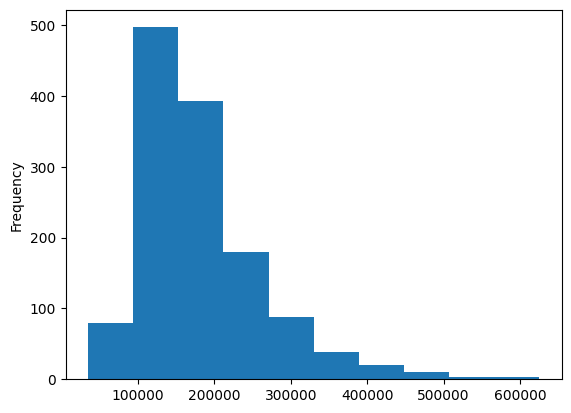

In [5]:
y_train.plot.hist()

Training on such targets is possible, but very large target values easily risk overflow, particularly
when a loss function like mean squared error is used. We will use the log-transform to transform this
distribution, as it's near-exponential, so it should bring it closer to normal, and also greatly reduce
the values range.

<Axes: ylabel='Frequency'>

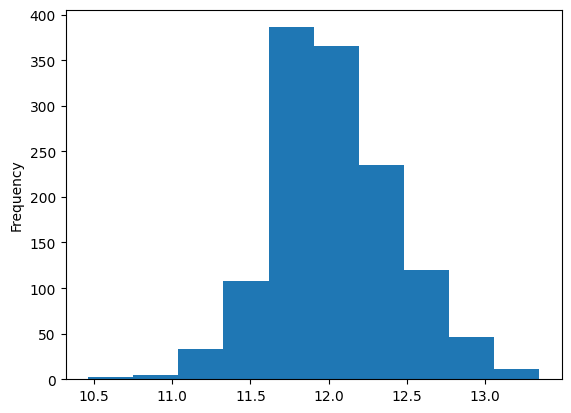

In [6]:
np.log1p(y_train).plot.hist()

Of course, we will need to transform the predictions back again to evaluate them. In scikit-learn,
[TransformedTargetRegressor](https://scikit-learn.org/stable/modules/generated/sklearn.compose.TransformedTargetRegressor.html)
does both steps for us.

### Training with autologging

Autologging is a powerful built-in capability of MLflow, enabling fully automated and near-zero code
integration of MLflow with many popular frameworks. In particular, it works really well with
scikit-learn, thanks to its highly unified API. Let's try this out - we will enable autologging,
and then train a bunch of different models.

We log the whole scikit-learn `Pipeline`, i.e. preprocessing together with the model. This way,
the logged model accepts raw data, exactly like the one we load from Parquet, and can be used
later without reimplementing the preprocessing.

In [7]:
# log models with input examples, we will log datasets manually later
AUTOLOG_KWARGS = {"log_input_examples": True, "log_datasets": False, "silent": True}

mlflow.sklearn.autolog(**AUTOLOG_KWARGS)

mlflow.set_experiment("ames-housing-autolog")

2026/11/13 16:49:04 INFO mlflow.tracking.fluent: Experiment with name 'ames-housing-autolog' does not exist. Creating a new experiment.


<Experiment: artifact_location='mlflow-artifacts:/1', creation_time=1794584944952, effective_trace_archival_retention=None, experiment_id='1', last_update_time=1794584944952, lifecycle_stage='active', name='ames-housing-autolog', tags={}, trace_location=None, workspace='default'>

In [8]:
from sklearn.ensemble import HistGradientBoostingRegressor, RandomForestRegressor
from sklearn.linear_model import Ridge
from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor


models = [
    ("Ridge Regression", Ridge()),
    ("Decision Tree", DecisionTreeRegressor(max_depth=10, random_state=42)),
    ("K-Nearest Neighbors", KNeighborsRegressor(n_neighbors=10)),
    ("Random Forest", RandomForestRegressor(n_estimators=100, random_state=42)),
    ("Histogram Gradient Boosting", HistGradientBoostingRegressor(random_state=42)),
]


def make_pipeline(model) -> Pipeline:
    # train on log-prices, return predictions in dollars
    regressor = TransformedTargetRegressor(
        regressor=model, func=np.log1p, inverse_func=np.expm1
    )
    return Pipeline(
        [("preprocessing", clone(column_transformer)), ("model", regressor)]
    )

Autologging patches every `fit()` call, including the ones made internally by `cross_val_score()`.
If we ran cross-validation inside a run, MLflow would log 5 additional fits and models into it, and
overwrite the training metrics of our final model. Therefore, we pause autologging for the time of
cross-validation.

In [16]:
from sklearn.metrics import root_mean_squared_error, mean_absolute_error, r2_score


def cross_validate_without_autolog(pipeline: Pipeline, X, y) -> np.ndarray:
    mlflow.sklearn.autolog(disable=True)
    try:
        return cross_val_score(pipeline, X, y, cv=5, scoring="r2")
    finally:
        mlflow.sklearn.autolog(**AUTOLOG_KWARGS)


def fit_sklearn_models(models, df_train, df_test, y_train, y_test):
    results = {}

    for model_name, model in models:
        pipeline = make_pipeline(model)

        # start MLflow run - a unit grouping logs from different model runs
        # everything within this context manager will get logged as a run
        with mlflow.start_run(run_name=model_name):
            cv_scores = cross_validate_without_autolog(pipeline, df_train, y_train)

            pipeline.fit(df_train, y_train)
            y_pred = pipeline.predict(df_test)

            metrics = {
                "cv_r2_mean": cv_scores.mean(),
                "cv_r2_std": cv_scores.std(),
                "test_rmse": root_mean_squared_error(y_test, y_pred),
                "test_mae": mean_absolute_error(y_test, y_pred),
                "test_r2": r2_score(y_test, y_pred),
            }
            # log additional custom metrics, in addition to autologging
            mlflow.log_metrics(metrics)

            results[model_name] = metrics

            print(f"\n{model_name}:")
            print(
                f"  CV R^2 (mean ± std): {metrics['cv_r2_mean']:.3f} ± {metrics['cv_r2_std']:.3f}"
            )
            print(f"  Test RMSE: {metrics['test_rmse']:.2f}")
            print(f"  Test MAE: {metrics['test_mae']:.2f}")
            print(f"  Test R^2: {metrics['test_r2']:.3f}")

    return results

In [10]:
sklearn_results = fit_sklearn_models(models, df_train, df_test, y_train, y_test)


Ridge Regression:
  CV R^2 (mean ± std): 0.912 ± 0.043
  Test RMSE: 20604.71
  Test MAE: 13581.70
  Test R^2: 0.926
🏃 View run Ridge Regression at: http://localhost:5001/#/experiments/1/runs/243fe5f006f1492f92bd23cb2497d532
🧪 View experiment at: http://localhost:5001/#/experiments/1

Decision Tree:
  CV R^2 (mean ± std): 0.731 ± 0.076
  Test RMSE: 37218.25
  Test MAE: 23082.59
  Test R^2: 0.758
🏃 View run Decision Tree at: http://localhost:5001/#/experiments/1/runs/dea8c2d355b34bcbaebd63450f4ec35e
🧪 View experiment at: http://localhost:5001/#/experiments/1

K-Nearest Neighbors:
  CV R^2 (mean ± std): 0.620 ± 0.026
  Test RMSE: 39498.81
  Test MAE: 26313.65
  Test R^2: 0.727
🏃 View run K-Nearest Neighbors at: http://localhost:5001/#/experiments/1/runs/318faead2ec94bfd84ea754d97557e38
🧪 View experiment at: http://localhost:5001/#/experiments/1

Random Forest:
  CV R^2 (mean ± std): 0.861 ± 0.038
  Test RMSE: 25143.23
  Test MAE: 15518.41
  Test R^2: 0.889
🏃 View run Random Forest at: ht

Open the MLflow dashboard at http://localhost:5001/ and go to the Experiments tab. On the left, you
have the experiment name, and when you select it, the list of all runs will show up. Click
through the interface and familiarize yourself with the most important elements:

1. What columns can be selected
2. Pick a particular run and check what values are logged automatically, e.g. parameters of every
   pipeline step
3. Select columns to compare a given metric between runs, e.g. `test_mae`
4. Sort algorithms by `cv_r2_mean` to pick the best one
5. Open the Models tab of the experiment - since MLflow 3, every logged model is a first-class
   object (`LoggedModel`), linked to the run that created it

Note that we select the best model by cross-validation score, not by test score. If we picked the
model with the best test score, the test set would become a part of model selection, and its score
would no longer be an unbiased estimate of performance on new data.

### Data lineage with DVC and MLflow

You've already used DVC to version your dataset in the first part of this lab. Now let's connect
DVC metadata with MLflow experiments to create a complete audit trail. When you run experiments,
you want to know:

- Which version of the data was used?
- Can I reproduce these exact results?
- What changed between experiments?

DVC stores metadata in `.dvc` files. Let's read it:

In [11]:
import yaml


def get_dvc_metadata(dvc_file_path):
    with open(dvc_file_path, "r") as f:
        dvc_data = yaml.safe_load(f)

    metadata = {
        "md5": dvc_data["outs"][0]["md5"],
        "size": dvc_data["outs"][0]["size"],
        "path": dvc_data["outs"][0]["path"],
    }
    return metadata


dvc_metadata = get_dvc_metadata(f"{DATA_PATH}.dvc")
print("DVC Metadata:")
print(f"MD5 hash: {dvc_metadata['md5']}")
print(f"File size: {dvc_metadata['size']} bytes")
print(f"Data path: {dvc_metadata['path']}")

DVC Metadata:
MD5 hash: f44053333f88a0646819936b37f000ee
File size: 162560 bytes
Data path: ames_data_2006_2008.parquet


MLflow has a built-in [dataset tracking](https://mlflow.org/docs/latest/ml/dataset/) mechanism.
We describe the dataset with `mlflow.data.from_pandas()` and attach it to a run with
`mlflow.log_input()`. The dataset is then shown in the Datasets column of the runs list, and you
can filter and compare runs by it. MLflow computes a digest (hash) of the data by default, but we
already have one from DVC. Using it as the digest links the run directly to a DVC data version.

In [12]:
dataset = mlflow.data.from_pandas(
    df,
    source=DATA_PATH,
    name="ames-2006-2008",
    digest=dvc_metadata["md5"],
    targets="SalePrice",
)
print(f"Dataset: {dataset.name}, digest: {dataset.digest}")

Dataset: ames-2006-2008, digest: f44053333f88a0646819936b37f000ee


When you run code from a script, MLflow automatically tags the run with the current Git commit. In
Jupyter notebooks this does not happen, so we need to read the commit ourselves:

In [13]:
import subprocess


def get_git_commit() -> str:
    result = subprocess.run(
        ["git", "rev-parse", "HEAD"], capture_output=True, text=True, check=True
    )
    return result.stdout.strip()


print(f"Git commit: {get_git_commit()}")

Git commit: 3622a376e9d321873aad1482986a94af9469f878


#### Exercise 3

We have trained 5 different models, and the results of all of them can be compared in MLflow. Now
let's link them with the code and data versions. This creates a complete audit trail:

- Git commit tracks code version
- DVC hash tracks data version
- MLflow run tracks experiment results

Your task is to:

1. Extend `fit_sklearn_models()`, so that every run logs the dataset with `mlflow.log_input()`
   (use `context="training"`) and sets the `mlflow.source.git.commit` tag to the current Git commit.
2. Run at least 3 more experiments with other models or hyperparameters. You can use any
   [supervised learning methods from scikit-learn](https://scikit-learn.org/stable/supervised_learning.html).
3. Create a new version of the dataset, e.g. remove houses with `GrLivArea` above 3000, or remove
   a few features that you consider noisy. Track it with DVC and commit the `.dvc` file. Then reload
   the data, rerun your two best models, and compare runs with different dataset digests in the
   MLflow UI.

---

In [17]:
def fit_sklearn_models(models, df_train, df_test, y_train, y_test, dataset):
    results = {}
    git_commit = get_git_commit()

    for model_name, model in models:
        pipeline = make_pipeline(model)

        # start MLflow run - a unit grouping logs from different model runs
        # everything within this context manager will get logged as a run
        with mlflow.start_run(run_name=model_name):
            mlflow.log_input(dataset, context="training")
            mlflow.set_tag("mlflow.source.git.commit", git_commit)

            cv_scores = cross_validate_without_autolog(pipeline, df_train, y_train)

            pipeline.fit(df_train, y_train)
            y_pred = pipeline.predict(df_test)

            metrics = {
                "cv_r2_mean": cv_scores.mean(),
                "cv_r2_std": cv_scores.std(),
                "test_rmse": root_mean_squared_error(y_test, y_pred),
                "test_mae": mean_absolute_error(y_test, y_pred),
                "test_r2": r2_score(y_test, y_pred),
            }
            # log additional custom metrics, in addition to autologging
            mlflow.log_metrics(metrics)

            results[model_name] = metrics

            print(f"\n{model_name}:")
            print(
                f"  CV R^2 (mean ± std): {metrics['cv_r2_mean']:.3f} ± {metrics['cv_r2_std']:.3f}"
            )
            print(f"  Test RMSE: {metrics['test_rmse']:.2f}")
            print(f"  Test MAE: {metrics['test_mae']:.2f}")
            print(f"  Test R^2: {metrics['test_r2']:.3f}")

    return results

In [18]:
sklearn_results = fit_sklearn_models(
    models, df_train, df_test, y_train, y_test, dataset
)


Ridge Regression:
  CV R^2 (mean ± std): 0.912 ± 0.043
  Test RMSE: 20604.71
  Test MAE: 13581.70
  Test R^2: 0.926
🏃 View run Ridge Regression at: http://localhost:5001/#/experiments/1/runs/57fc3f28c9a04a7bbca8325ce6876750
🧪 View experiment at: http://localhost:5001/#/experiments/1

Decision Tree:
  CV R^2 (mean ± std): 0.731 ± 0.076
  Test RMSE: 37218.25
  Test MAE: 23082.59
  Test R^2: 0.758
🏃 View run Decision Tree at: http://localhost:5001/#/experiments/1/runs/ef25183d6bf14a82be4dd74a924fd48e
🧪 View experiment at: http://localhost:5001/#/experiments/1

K-Nearest Neighbors:
  CV R^2 (mean ± std): 0.620 ± 0.026
  Test RMSE: 39498.81
  Test MAE: 26313.65
  Test R^2: 0.727
🏃 View run K-Nearest Neighbors at: http://localhost:5001/#/experiments/1/runs/6ed74f509175498aad1f4bc589388bae
🧪 View experiment at: http://localhost:5001/#/experiments/1

Random Forest:
  CV R^2 (mean ± std): 0.861 ± 0.038
  Test RMSE: 25143.23
  Test MAE: 15518.41
  Test R^2: 0.889
🏃 View run Random Forest at: ht

In [19]:
from sklearn.linear_model import Lasso, ElasticNet
from sklearn.ensemble import GradientBoostingRegressor

new_models = [
    ("Lasso", Lasso(alpha=0.001)),
    ("ElasticNet", ElasticNet(alpha=0.001, l1_ratio=0.5)),
    ("Gradient Boosting", GradientBoostingRegressor(random_state=42)),
]
new_results = fit_sklearn_models(
    new_models, df_train, df_test, y_train, y_test, dataset
)


Lasso:
  CV R^2 (mean ± std): 0.913 ± 0.029
  Test RMSE: 20000.83
  Test MAE: 13835.16
  Test R^2: 0.930
🏃 View run Lasso at: http://localhost:5001/#/experiments/1/runs/37a7af4bf5ea43088564c4a2dee00a9d
🧪 View experiment at: http://localhost:5001/#/experiments/1

ElasticNet:
  CV R^2 (mean ± std): 0.915 ± 0.036
  Test RMSE: 19715.07
  Test MAE: 13498.48
  Test R^2: 0.932
🏃 View run ElasticNet at: http://localhost:5001/#/experiments/1/runs/8feebc91632243a2a47cd6706c8e028c
🧪 View experiment at: http://localhost:5001/#/experiments/1

Gradient Boosting:
  CV R^2 (mean ± std): 0.892 ± 0.031
  Test RMSE: 21727.33
  Test MAE: 14309.59
  Test R^2: 0.917
🏃 View run Gradient Boosting at: http://localhost:5001/#/experiments/1/runs/b04d5ce3c37748ccaa1c12fe8268d96c
🧪 View experiment at: http://localhost:5001/#/experiments/1


In [20]:
df_v2 = df[df["GrLivArea"] <= 3000]
df_v2.to_parquet(DATA_PATH)

In [21]:
DATA_PATH = "data/ames_data_2006_2008.parquet"

df = pd.read_parquet(DATA_PATH)

# As we have temporal data, the best way to evaluate our model is time (chronological)
# split, where the newest data is used for testing. We will assume that we have the
# data for years 2006 and 2007, and evaluate using data from 2008.

df_train = df[df["YrSold"] < 2008]
df_test = df[df["YrSold"] == 2008]

y_train = df_train.pop("SalePrice")
y_test = df_test.pop("SalePrice")

categorical_features = df_train.select_dtypes(include="object").columns
numerical_features = df_train.select_dtypes(exclude="object").columns

print(f"Training samples: {df_train.shape[0]}")
print(f"Test samples: {df_test.shape[0]}")
print(f"Raw features: {df_train.shape[1]}")

Training samples: 1300
Test samples: 618
Raw features: 79


In [22]:
median_imputer = SimpleImputer(strategy="median")
min_max_scaler = MinMaxScaler()
rare_encoder = RareLabelEncoder(tol=0.01, n_categories=0)
one_hot_encoder = OneHotEncoder(
    drop="first", sparse_output=False, handle_unknown="ignore"
)

num_pipeline = Pipeline(
    [("median_imputer", median_imputer), ("min_max_scaler", min_max_scaler)]
)

cat_pipeline = Pipeline(
    [("rare_encoder", rare_encoder), ("one_hot_encoder", one_hot_encoder)]
)

column_transformer = ColumnTransformer(
    [
        ("num_pipeline", num_pipeline, numerical_features),
        ("cat_pipeline", cat_pipeline, categorical_features),
    ],
    verbose_feature_names_out=False,
)

In [ ]:
dvc_metadata = get_dvc_metadata(f"{DATA_PATH}.dvc")
print("DVC Metadata:")
print(f"MD5 hash: {dvc_metadata['md5']}")
print(f"File size: {dvc_metadata['size']} bytes")
print(f"Data path: {dvc_metadata['path']}")

DVC Metadata:
MD5 hash: 3ca25ae24543d01775947a19e852cb92
File size: 161134 bytes
Data path: ames_data_2006_2008.parquet


In [24]:
dataset = mlflow.data.from_pandas(
    df,
    source=DATA_PATH,
    name="ames-2006-2008",
    digest=dvc_metadata["md5"],
    targets="SalePrice",
)
print(f"Dataset: {dataset.name}, digest: {dataset.digest}")

Dataset: ames-2006-2008, digest: 3ca25ae24543d01775947a19e852cb92


In [27]:
mlflow.sklearn.autolog(**AUTOLOG_KWARGS)
mlflow.set_experiment("ames-housing-autolog")

<Experiment: artifact_location='mlflow-artifacts:/1', creation_time=1794584944952, effective_trace_archival_retention=None, experiment_id='1', last_update_time=1794584944952, lifecycle_stage='active', name='ames-housing-autolog', tags={}, trace_location=None, workspace='default'>

In [28]:
best_two_models = [
    ("Lasso", Lasso(alpha=0.001)),
    ("ElasticNet", ElasticNet(alpha=0.001, l1_ratio=0.5)),
]

v2_results = fit_sklearn_models(
    best_two_models, df_train, df_test, y_train, y_test, dataset
)


Lasso:
  CV R^2 (mean ± std): 0.911 ± 0.026
  Test RMSE: 19974.80
  Test MAE: 13846.63
  Test R^2: 0.929
🏃 View run Lasso at: http://localhost:5001/#/experiments/1/runs/46800c7e0685441a975cfe94f81b1173
🧪 View experiment at: http://localhost:5001/#/experiments/1

ElasticNet:
  CV R^2 (mean ± std): 0.914 ± 0.032
  Test RMSE: 19677.77
  Test MAE: 13548.90
  Test R^2: 0.931
🏃 View run ElasticNet at: http://localhost:5001/#/experiments/1/runs/40d322cae55f4b9b84426c5716baaf18
🧪 View experiment at: http://localhost:5001/#/experiments/1


![20 runs](mlflow_screen/ex3.png)

## Manual logging with PyTorch

In this section, we'll implement manual logging for PyTorch models. While scikit-learn has autologging,
PyTorch requires manual tracking - giving us full control over what and when to log. MLflow supports
autologging for [PyTorch Lightning](https://lightning.ai/docs/pytorch/stable/), but we often need
low-level control of pure PyTorch.

Note that we need to turn off scikit-learn autologging! Since we are using a Jupyter Notebook, MLflow
uses the previously configured autologging unless explicitly turned off.

In [29]:
import copy

import torch
import torch.nn as nn
from tabm import TabM
from torch.utils.data import DataLoader, TensorDataset

# disable sklearn autologging!
mlflow.sklearn.autolog(disable=True)

mlflow.set_experiment("pytorch-housing-manual")

2026/11/13 19:23:17 INFO mlflow.tracking.fluent: Experiment with name 'pytorch-housing-manual' does not exist. Creating a new experiment.


<Experiment: artifact_location='mlflow-artifacts:/2', creation_time=1794594198009, effective_trace_archival_retention=None, experiment_id='2', last_update_time=1794594198009, lifecycle_stage='active', name='pytorch-housing-manual', tags={}, trace_location=None, workspace='default'>

### Data preparation

Neural networks need a validation set for early stopping, i.e. stopping the training when the
validation error stops improving. We hold out 20% of the training data for that purpose, while
the 2008 data stays our test set.

We use log-prices as targets, as before. Additionally, we standardize them to zero mean and unit
variance. Log-prices are around 12, and a freshly initialized network outputs values around 0, so
without standardization, a large part of the training would be spent just on shifting the outputs.

In [30]:
X_train = column_transformer.fit_transform(df_train)
X_test = column_transformer.transform(df_test)

X_tr, X_val, y_tr, y_val = train_test_split(
    X_train, np.log1p(y_train), test_size=0.2, random_state=42
)

# standardization parameters are computed on training data only
y_log_mean, y_log_std = y_tr.mean(), y_tr.std()


def to_tensors(X: np.ndarray, y_log: pd.Series) -> tuple[torch.Tensor, torch.Tensor]:
    y_standardized = (y_log.to_numpy() - y_log_mean) / y_log_std
    return (
        torch.tensor(X, dtype=torch.float32),
        torch.tensor(y_standardized, dtype=torch.float32).reshape(-1, 1),
    )


train_data = to_tensors(X_tr, y_tr)
val_data = to_tensors(X_val, y_val)
test_data = to_tensors(X_test, np.log1p(y_test))

print(f"Train: {len(X_tr)}, validation: {len(X_val)}, test: {len(X_test)}")
print(f"Number of features: {X_train.shape[1]}")

Train: 1040, validation: 260, test: 618
Number of features: 182


### Models: MLP baseline and TabM

As a baseline, we will use a simple 2-layer multilayer perceptron (MLP).

In [31]:
class HousePriceNet(nn.Module):
    def __init__(
        self, input_dim: int, hidden_dim: int = 128, dropout_rate: float = 0.2
    ):
        super().__init__()
        self.fc1 = nn.Linear(input_dim, hidden_dim)
        self.relu = nn.ReLU()
        self.dropout = nn.Dropout(dropout_rate)
        self.fc2 = nn.Linear(hidden_dim, 1)

    def forward(self, x):
        x = self.fc1(x)
        x = self.relu(x)
        x = self.dropout(x)
        x = self.fc2(x)
        return x

For a long time, plain MLPs were clearly worse than gradient boosting on tabular data. Recent tabular
deep learning models have closed much of that gap.
[TabM](https://github.com/yandex-research/tabm) ([paper, ICLR 2025](https://arxiv.org/abs/2410.24210))
is one of the strongest and simplest of them. It is an MLP that efficiently imitates an ensemble of
`k` MLPs (by default `k=32`). Most weights are shared between submodels, so it costs only a bit more
than a single MLP. A few things to note:

- output has shape `(batch, k, 1)` - one prediction per submodel
- during training, each submodel gets its own loss, and we minimize their mean, not the loss of the
  mean prediction
- during inference, the final prediction is the mean of the submodels' predictions

To use both models with the same training code, we treat the MLP as an "ensemble" with `k=1`.

In [32]:
def create_model(config: dict, n_features: int) -> nn.Module:
    if config["model"] == "mlp":
        return HousePriceNet(
            input_dim=n_features,
            hidden_dim=config["d_block"],
            dropout_rate=config["dropout"],
        )
    elif config["model"] == "tabm":
        return TabM.make(
            n_num_features=n_features,
            d_out=1,
            n_blocks=config["n_blocks"],
            d_block=config["d_block"],
            dropout=config["dropout"],
        )
    raise ValueError(f"Unknown model: {config['model']}")

### Training with manual logging

The trainer logs training and validation losses for each epoch, which shows the learning curves
in the MLflow UI. It also implements early stopping: the training stops when the validation RMSE
has not improved for `patience` epochs, and the weights from the best epoch are restored.

In [33]:
class PyTorchTrainer:
    def __init__(self, config: dict):
        self.config = config

    @staticmethod
    def predict(model: nn.Module, X: torch.Tensor) -> torch.Tensor:
        # shape (batch, k): MLP has k=1, TabM has k submodels
        return model(X).reshape(len(X), -1)

    def train_epoch(
        self, model: nn.Module, loader: DataLoader, optimizer: torch.optim.Optimizer
    ) -> float:
        model.train()
        total_loss = 0.0

        for X_batch, y_batch in loader:
            optimizer.zero_grad()
            y_pred = self.predict(model, X_batch)
            # mean of submodels' losses, not loss of the mean prediction
            loss = nn.functional.mse_loss(y_pred, y_batch.expand_as(y_pred))
            loss.backward()
            optimizer.step()
            total_loss += loss.item() * len(X_batch)

        return total_loss / len(loader.dataset)

    @torch.no_grad()
    def evaluate(
        self, model: nn.Module, X: torch.Tensor, y: torch.Tensor
    ) -> dict[str, float]:
        model.eval()
        y_pred = self.predict(model, X).mean(dim=1, keepdim=True)

        # revert standardization and logarithm to compute errors in dollars
        y_pred_dollars = np.expm1(y_pred.numpy().ravel() * y_log_std + y_log_mean)
        y_true_dollars = np.expm1(y.numpy().ravel() * y_log_std + y_log_mean)

        return {
            "loss": nn.functional.mse_loss(y_pred, y).item(),
            "rmse": root_mean_squared_error(y_true_dollars, y_pred_dollars),
            "mae": mean_absolute_error(y_true_dollars, y_pred_dollars),
            "r2": r2_score(y_true_dollars, y_pred_dollars),
        }

    def fit(
        self,
        train_data: tuple[torch.Tensor, torch.Tensor],
        val_data: tuple[torch.Tensor, torch.Tensor],
    ) -> tuple[nn.Module, dict[str, float]]:
        torch.manual_seed(self.config["random_seed"])

        X_train, y_train = train_data
        model = create_model(self.config, n_features=X_train.shape[1])
        optimizer = torch.optim.AdamW(
            model.parameters(),
            lr=self.config["learning_rate"],
            weight_decay=self.config["weight_decay"],
        )
        loader = DataLoader(
            TensorDataset(X_train, y_train),
            batch_size=self.config["batch_size"],
            shuffle=True,
        )

        best_metrics, best_state, best_epoch = None, None, 0
        for epoch in range(self.config["max_epochs"]):
            train_loss = self.train_epoch(model, loader, optimizer)
            val_metrics = self.evaluate(model, *val_data)

            # manually log metric values, with the epoch as the step
            mlflow.log_metrics(
                {
                    "train_loss": train_loss,
                    "val_loss": val_metrics["loss"],
                    "val_rmse": val_metrics["rmse"],
                },
                step=epoch,
            )

            if best_metrics is None or val_metrics["rmse"] < best_metrics["rmse"]:
                best_metrics, best_epoch = val_metrics, epoch
                best_state = copy.deepcopy(model.state_dict())
            elif epoch - best_epoch >= self.config["patience"]:
                break

        model.load_state_dict(best_state)
        mlflow.log_metric("best_epoch", best_epoch)
        mlflow.log_metrics(
            {f"best_val_{name}": value for name, value in best_metrics.items()}
        )

        return model, best_metrics

The `train_and_log()` function runs the whole experiment in a single MLflow run. Note that we log
the trained network with `mlflow.pytorch.log_model()`, with an input example, from which MLflow
infers the model signature.

In [34]:
def train_and_log(config: dict) -> dict[str, float]:
    with mlflow.start_run(run_name=config["name"]):
        mlflow.log_params(config)

        trainer = PyTorchTrainer(config)
        model, val_metrics = trainer.fit(train_data, val_data)

        test_metrics = trainer.evaluate(model, *test_data)
        mlflow.log_metrics(
            {f"test_{name}": value for name, value in test_metrics.items()}
        )

        mlflow.pytorch.log_model(
            model, name=config["model"], input_example=val_data[0][:5].numpy()
        )

        print(
            f"{config['name']}: "
            f"validation RMSE {val_metrics['rmse']:.2f}, "
            f"test RMSE {test_metrics['rmse']:.2f}, "
            f"test R^2 {test_metrics['r2']:.3f}"
        )
        return test_metrics

`base_config` contains **fixed parameters** that stay the same across all experiments:

- `random_seed` - for reproducibility
- `max_epochs` - upper limit of training epochs
- `patience` - number of epochs without improvement before early stopping
- `batch_size` - number of samples per training batch
- `learning_rate` and `weight_decay` - AdamW optimizer settings
- `dropout` - dropout rate for regularization

Model configurations add the model type and its size. We use Python's dictionary merge operator `|`
to combine them, where the values on the right override any duplicate keys from `base_config`:

In [35]:
base_config = {
    "random_seed": 42,
    "max_epochs": 200,
    "patience": 10,
    "batch_size": 64,
    "learning_rate": 1e-3,
    "weight_decay": 1e-4,
    "dropout": 0.1,
}

mlp_config = base_config | {"name": "mlp_baseline", "model": "mlp", "d_block": 128}
tabm_config = base_config | {
    "name": "tabm_default",
    "model": "tabm",
    "n_blocks": 3,
    "d_block": 128,
}

for config in [mlp_config, tabm_config]:
    train_and_log(config)

2026/11/13 19:42:58 INFO mlflow.utils.uv_utils: Detected uv project: found uv.lock and pyproject.toml in /home/jhyla/MLOps/lab05
2026/11/13 19:43:01 WARNING mlflow.utils.requirements_utils: Found torch version (2.7.1+cpu) contains a local version label (+cpu). MLflow logged a pip requirement for this package as 'torch==2.7.1' without the local version label to make it installable from PyPI. To specify pip requirements containing local version labels, please use `conda_env` or `pip_requirements`.
2026/11/13 19:43:01 INFO mlflow.utils.uv_utils: Detected uv project: found uv.lock and pyproject.toml in /home/jhyla/MLOps/lab05
2026/11/13 19:43:01 INFO mlflow.utils.environment: Detected uv project at /home/jhyla/MLOps/lab05. Attempting to export requirements via 'uv export'.
2026/11/13 19:43:01 INFO mlflow.utils.uv_utils: Exported 246 dependencies via uv
2026/11/13 19:43:01 INFO mlflow.utils.environment: Successfully exported 246 requirements from uv project. Skipping package capture based i

mlp_baseline: validation RMSE 20229.47, test RMSE 22206.42, test R^2 0.912
🏃 View run mlp_baseline at: http://localhost:5001/#/experiments/2/runs/f64b39b9df5341de96ba70430626d855
🧪 View experiment at: http://localhost:5001/#/experiments/2


2026/11/13 19:45:21 INFO mlflow.utils.uv_utils: Detected uv project: found uv.lock and pyproject.toml in /home/jhyla/MLOps/lab05
2026/11/13 19:45:23 WARNING mlflow.utils.requirements_utils: Found torch version (2.7.1+cpu) contains a local version label (+cpu). MLflow logged a pip requirement for this package as 'torch==2.7.1' without the local version label to make it installable from PyPI. To specify pip requirements containing local version labels, please use `conda_env` or `pip_requirements`.
2026/11/13 19:45:23 INFO mlflow.utils.uv_utils: Detected uv project: found uv.lock and pyproject.toml in /home/jhyla/MLOps/lab05
2026/11/13 19:45:23 INFO mlflow.utils.environment: Detected uv project at /home/jhyla/MLOps/lab05. Attempting to export requirements via 'uv export'.
2026/11/13 19:45:23 INFO mlflow.utils.uv_utils: Exported 246 dependencies via uv
2026/11/13 19:45:23 INFO mlflow.utils.environment: Successfully exported 246 requirements from uv project. Skipping package capture based i

tabm_default: validation RMSE 19872.02, test RMSE 21390.52, test R^2 0.919
🏃 View run tabm_default at: http://localhost:5001/#/experiments/2/runs/a1eaf43102c14390b7004c2cdce99f18
🧪 View experiment at: http://localhost:5001/#/experiments/2


Open the `pytorch-housing-manual` experiment in the MLflow UI. Select both runs and compare their
`train_loss` and `val_loss` curves in the Chart view. Notice when the validation loss stops
decreasing while the training loss keeps going down - this is the moment when the model starts
overfitting, and early stopping kicks in shortly after.

## Hyperparameter optimization with Optuna

Choosing hyperparameters by hand quickly becomes tedious and does not scale.
[Optuna](https://optuna.org/) automates this: we define an objective function, which trains a model
with hyperparameters suggested by Optuna and returns the validation error, and Optuna searches for
the best values. By default, it uses the
[Tree-structured Parzen Estimator (TPE)](https://optuna.readthedocs.io/en/stable/reference/samplers/generated/optuna.samplers.TPESampler.html)
algorithm, which focuses on promising regions of the search space based on previous trials.

Each Optuna trial is logged as a **nested run**, a child of the run representing the whole study.
The MLflow UI groups child runs under their parent, so a whole study stays readable even with
dozens of trials. Note that the objective uses only the validation set - the test set is not used
for any decisions. We also enqueue our current configuration as the first trial, so the search
starts from a known baseline and can only improve on it.

In [36]:
import optuna

optuna.logging.set_verbosity(optuna.logging.WARNING)


def objective(trial: optuna.Trial) -> float:
    config = base_config | {
        "name": f"trial_{trial.number}",
        "model": "tabm",
        "n_blocks": 3,
        "d_block": 128,
        "learning_rate": trial.suggest_float("learning_rate", 1e-4, 1e-2, log=True),
        "dropout": trial.suggest_float("dropout", 0.0, 0.5),
    }

    with mlflow.start_run(run_name=config["name"], nested=True):
        mlflow.log_params(config)
        _, val_metrics = PyTorchTrainer(config).fit(train_data, val_data)

    return val_metrics["rmse"]


with mlflow.start_run(run_name="optuna_tabm"):
    study = optuna.create_study(
        direction="minimize", sampler=optuna.samplers.TPESampler(seed=42)
    )
    study.enqueue_trial(
        {
            "learning_rate": base_config["learning_rate"],
            "dropout": base_config["dropout"],
        }
    )
    study.optimize(objective, n_trials=5)

    mlflow.log_params(study.best_params)
    mlflow.log_metric("best_val_rmse", study.best_value)

print(f"Best validation RMSE: {study.best_value:.2f}")
print(f"Best hyperparameters: {study.best_params}")

🏃 View run trial_0 at: http://localhost:5001/#/experiments/2/runs/92f2b5f166ec43768b1f3b71a6f2d7b7
🧪 View experiment at: http://localhost:5001/#/experiments/2
🏃 View run trial_1 at: http://localhost:5001/#/experiments/2/runs/05c0245b7e914dc7a87b29fdb8ff73d9
🧪 View experiment at: http://localhost:5001/#/experiments/2
🏃 View run trial_2 at: http://localhost:5001/#/experiments/2/runs/e05581af093d48f2ac75fda475e96c55
🧪 View experiment at: http://localhost:5001/#/experiments/2
🏃 View run trial_3 at: http://localhost:5001/#/experiments/2/runs/29dbcb16754d44ee89a1126b903c2c10
🧪 View experiment at: http://localhost:5001/#/experiments/2
🏃 View run trial_4 at: http://localhost:5001/#/experiments/2/runs/46d7a4755df749b0acde18bded6a745b
🧪 View experiment at: http://localhost:5001/#/experiments/2
🏃 View run optuna_tabm at: http://localhost:5001/#/experiments/2/runs/5c86eb43a10e428c9275961668607fce
🧪 View experiment at: http://localhost:5001/#/experiments/2
Best validation RMSE: 19872.02
Best hyperp

With only 5 trials and 2 hyperparameters, the study may not find anything better than our
baseline - a real search needs more trials and a wider search space. Finally, we train the model
with the best hyperparameters and evaluate it on the test set:

In [37]:
best_tabm_config = base_config | {
    "name": "tabm_optuna_best",
    "model": "tabm",
    "n_blocks": 3,
    "d_block": 128,
    **study.best_params,
}
train_and_log(best_tabm_config)

2026/11/13 20:01:41 INFO mlflow.utils.uv_utils: Detected uv project: found uv.lock and pyproject.toml in /home/jhyla/MLOps/lab05
2026/11/13 20:01:43 WARNING mlflow.utils.requirements_utils: Found torch version (2.7.1+cpu) contains a local version label (+cpu). MLflow logged a pip requirement for this package as 'torch==2.7.1' without the local version label to make it installable from PyPI. To specify pip requirements containing local version labels, please use `conda_env` or `pip_requirements`.
2026/11/13 20:01:43 INFO mlflow.utils.uv_utils: Detected uv project: found uv.lock and pyproject.toml in /home/jhyla/MLOps/lab05
2026/11/13 20:01:43 INFO mlflow.utils.environment: Detected uv project at /home/jhyla/MLOps/lab05. Attempting to export requirements via 'uv export'.
2026/11/13 20:01:43 INFO mlflow.utils.uv_utils: Exported 246 dependencies via uv
2026/11/13 20:01:43 INFO mlflow.utils.environment: Successfully exported 246 requirements from uv project. Skipping package capture based i

tabm_optuna_best: validation RMSE 19872.02, test RMSE 21390.52, test R^2 0.919
🏃 View run tabm_optuna_best at: http://localhost:5001/#/experiments/2/runs/c00e234c61e244cb9f6748ceb40cfca4
🧪 View experiment at: http://localhost:5001/#/experiments/2


{'loss': 0.11635373532772064,
 'rmse': 21390.522187504423,
 'mae': 14021.55858809245,
 'r2': 0.9187999196166784}

#### Exercise 4

Your task is to:

1. Extend the search space with `n_blocks` (1-4), `d_block` (64-256), `weight_decay`, and `batch_size`,
   and run at least 20 trials. On a laptop CPU, this takes around 5-10 minutes. Optionally, speed it
   up with [pruning](https://optuna.readthedocs.io/en/stable/tutorial/10_key_features/003_efficient_optimization_algorithms.html),
   i.e. reporting the validation RMSE after each epoch with `trial.report()` and stopping
   unpromising trials early when `trial.should_prune()` returns `True`.
2. Analyze the study in the MLflow UI. Select the child runs of your study and use the parallel
   coordinates chart to check which hyperparameters influence the validation RMSE the most.
3. Train the best configuration with `train_and_log()`, and compare the MLP baseline, the best TabM
   model, and the best scikit-learn model by their test metrics. Present the results in a table.
4. Comment on the results. Do you see signs of overfitting in the learning curves? Which hyperparameters
   helped against it? Is the deep learning model worth its complexity here?

---

In [38]:
def objective(trial: optuna.Trial) -> float:
    config = base_config | {
        "name": f"trial_{trial.number}",
        "model": "tabm",
        "n_blocks": trial.suggest_int("n_blocks", 1, 4),
        "d_block": trial.suggest_int("d_block", 64, 256, step=32),
        "learning_rate": trial.suggest_float("learning_rate", 1e-4, 1e-2, log=True),
        "dropout": trial.suggest_float("dropout", 0.0, 0.5),
        "weight_decay": trial.suggest_float("weight_decay", 1e-6, 1e-2, log=True),
        "batch_size": trial.suggest_categorical("batch_size", [32, 64, 128]),
    }

    with mlflow.start_run(run_name=config["name"], nested=True):
        mlflow.log_params(config)
        _, val_metrics = PyTorchTrainer(config).fit(train_data, val_data)

    return val_metrics["rmse"]


with mlflow.start_run(run_name="optuna_tabm_20"):
    study = optuna.create_study(
        direction="minimize", sampler=optuna.samplers.TPESampler(seed=42)
    )

    study.enqueue_trial(
        {
            "n_blocks": 3,
            "d_block": 128,
            "learning_rate": 1e-3,
            "dropout": 0.1,
            "weight_decay": 1e-4,
            "batch_size": 64,
        }
    )

    study.optimize(objective, n_trials=20)

    mlflow.log_params(study.best_params)
    mlflow.log_metric("best_val_rmse", study.best_value)

print(f"Best validation RMSE: {study.best_value:.2f}")
print(f"Best hyperparameters: {study.best_params}")

🏃 View run trial_0 at: http://localhost:5001/#/experiments/2/runs/433f393c4346493ba16e8da20aa5d5d1
🧪 View experiment at: http://localhost:5001/#/experiments/2
🏃 View run trial_1 at: http://localhost:5001/#/experiments/2/runs/54ac06c709874274b71ae3fde3ace405
🧪 View experiment at: http://localhost:5001/#/experiments/2
🏃 View run trial_2 at: http://localhost:5001/#/experiments/2/runs/d69ee517e81146528626186dcd2b11be
🧪 View experiment at: http://localhost:5001/#/experiments/2
🏃 View run trial_3 at: http://localhost:5001/#/experiments/2/runs/cbb3eafe2712477db8f4a9aa0f443351
🧪 View experiment at: http://localhost:5001/#/experiments/2
🏃 View run trial_4 at: http://localhost:5001/#/experiments/2/runs/33aeeb507d544ee79261161ca9528107
🧪 View experiment at: http://localhost:5001/#/experiments/2
🏃 View run trial_5 at: http://localhost:5001/#/experiments/2/runs/95b351a6637949b1b8347bf6012857f2
🧪 View experiment at: http://localhost:5001/#/experiments/2
🏃 View run trial_6 at: http://localhost:5001/#

In [39]:
best_tabm_config = base_config | {
    "name": "tabm_optuna_best_20",
    "model": "tabm",
    **study.best_params,
}
tabm_metrics = train_and_log(best_tabm_config)
mlp_metrics = train_and_log(mlp_config)

2026/11/13 21:04:25 INFO mlflow.utils.uv_utils: Detected uv project: found uv.lock and pyproject.toml in /home/jhyla/MLOps/lab05
2026/11/13 21:04:26 WARNING mlflow.utils.requirements_utils: Found torch version (2.7.1+cpu) contains a local version label (+cpu). MLflow logged a pip requirement for this package as 'torch==2.7.1' without the local version label to make it installable from PyPI. To specify pip requirements containing local version labels, please use `conda_env` or `pip_requirements`.
2026/11/13 21:04:26 INFO mlflow.utils.uv_utils: Detected uv project: found uv.lock and pyproject.toml in /home/jhyla/MLOps/lab05
2026/11/13 21:04:26 INFO mlflow.utils.environment: Detected uv project at /home/jhyla/MLOps/lab05. Attempting to export requirements via 'uv export'.
2026/11/13 21:04:26 INFO mlflow.utils.uv_utils: Exported 246 dependencies via uv
2026/11/13 21:04:26 INFO mlflow.utils.environment: Successfully exported 246 requirements from uv project. Skipping package capture based i

tabm_optuna_best_20: validation RMSE 19425.22, test RMSE 21176.06, test R^2 0.920
🏃 View run tabm_optuna_best_20 at: http://localhost:5001/#/experiments/2/runs/6b353d80908a489fab97e90ea81c7788
🧪 View experiment at: http://localhost:5001/#/experiments/2


2026/11/13 21:04:41 INFO mlflow.utils.uv_utils: Detected uv project: found uv.lock and pyproject.toml in /home/jhyla/MLOps/lab05
2026/11/13 21:04:42 WARNING mlflow.utils.requirements_utils: Found torch version (2.7.1+cpu) contains a local version label (+cpu). MLflow logged a pip requirement for this package as 'torch==2.7.1' without the local version label to make it installable from PyPI. To specify pip requirements containing local version labels, please use `conda_env` or `pip_requirements`.
2026/11/13 21:04:42 INFO mlflow.utils.uv_utils: Detected uv project: found uv.lock and pyproject.toml in /home/jhyla/MLOps/lab05
2026/11/13 21:04:42 INFO mlflow.utils.environment: Detected uv project at /home/jhyla/MLOps/lab05. Attempting to export requirements via 'uv export'.
2026/11/13 21:04:42 INFO mlflow.utils.uv_utils: Exported 246 dependencies via uv
2026/11/13 21:04:42 INFO mlflow.utils.environment: Successfully exported 246 requirements from uv project. Skipping package capture based i

mlp_baseline: validation RMSE 20229.47, test RMSE 22206.42, test R^2 0.912
🏃 View run mlp_baseline at: http://localhost:5001/#/experiments/2/runs/8248f7c37a9b4578b9aff743c52628aa
🧪 View experiment at: http://localhost:5001/#/experiments/2


In [46]:
best_sk = max(v2_results, key=lambda k: v2_results[k]["cv_r2_mean"])
sk_metrics = {
    k.removeprefix("test_"): v
    for k, v in v2_results[best_sk].items()
    if k.startswith("test_")
}

table = pd.DataFrame(
    {
        "MLP baseline": mlp_metrics,
        f"Best sklearn ({best_sk})": sk_metrics,
        "TabM (Optuna)": tabm_metrics,
    }
).T[["rmse", "mae", "r2"]]
table.round(2)

,rmse,mae,r2
MLP baseline,22206.42,15502.46,0.91
Best sklearn (ElasticNet),19677.77,13548.90,0.93
TabM (Optuna),21176.06,14157.39,0.92


![20 runs](mlflow_screen/ex4-20runs.png)

![best_params](mlflow_screen/ex4-best_params.png)

![worst_params](mlflow_screen/ex4-worst_params.png)

![line_charts](mlflow_screen/ex4-line_charts.png)

#### Which hyperparameters influence the validation RMSE the most?

Dwa najlepsze przebiegi mają wspólne d_block = 192 oraz batch_size = 64. Wysoki dropout występuje głównie w słabszych przebiegach.

#### Comment on the results. Do you see signs of overfitting in the learning curves? Which hyperparameters helped against it? Is the deep learning model worth its complexity here?

Tak, pojawia się delikatny overfitting (pod koniec treningu train_loss wynosi ok. 0,02, a val_loss ok. 0,08–0,09 (niezbyt widać to na powyższym screenshocie, ale dokładne wartości są widoczne w MLFlow), ale val_loss tylko się spłaszcza i nie rośnie, a early stopping zakończył trening po 71 (MLP) i 89 (TabM) epokach przy limicie 200 ).

Optuna znalazła konfigurację bliską domyślnej (dropout 0,034, weight_decay 1,6e-4, d_block 192, batch 64), która poprawiła val RMSE tylko z 19872 do 19425, a test RMSE z 21391 do 21176, więc główną ochroną przed overfittingiem był early stopping, a wysoki dropout częściej dawał gorsze wyniki.

Na teście TabM (RMSE 21176) wygrywa z MLP (22206), ale przegrywa z ElasticNet (19 678), który ma też lepsze MAE (13549 vs 14157) i R² (0,931 vs 0,920). W tym zadaniu przy głęboki model nie uzasadnia więc swojej złożoności.



## Model Registry

So far, models are logged in runs, and to use one, we would need to know its ID. The
[MLflow Model Registry](https://mlflow.org/docs/latest/ml/model-registry/) is a central catalog of
models intended for use. A **registered model** has a name, e.g. `ames-price`, and consists of
numbered **versions**, each pointing to a logged model. Versions can be marked with **aliases**,
e.g. `champion` for the production model and `challenger` for a candidate. Applications load models
by alias, e.g. `models:/ames-price@champion`. Promoting a new model just moves the alias, without
any change in the application code. Aliases replaced the deprecated "Staging" and "Production"
stages from MLflow 2.

We register the scikit-learn pipelines, since they include preprocessing and accept raw data. The
logged PyTorch networks expect already preprocessed features and return standardized log-prices, so
they cannot be used on their own by an application.

Let's find the best scikit-learn run by cross-validation score. Since MLflow 3, a logged model has
its own ID and URI (`models:/<model_id>`), independent of the run, so we look up the model logged
by that run and register it:

In [68]:
from mlflow import MlflowClient

MODEL_NAME = "ames-price"
client = MlflowClient()

runs = mlflow.search_runs(
    experiment_names=["ames-housing-autolog"],
    filter_string="metrics.cv_r2_mean > 0",
    order_by=["metrics.cv_r2_mean DESC"],
)
best_run = runs.iloc[0]
print(
    f"Best run: {best_run['tags.mlflow.runName']}, CV R^2: {best_run['metrics.cv_r2_mean']:.3f}"
)

logged_model = mlflow.search_logged_models(
    experiment_ids=[best_run["experiment_id"]],
    filter_string=f"source_run_id = '{best_run['run_id']}'",
    output_format="list",
)[0]
print(f"Logged model URI: {logged_model.model_uri}")

model_version = mlflow.register_model(logged_model.model_uri, MODEL_NAME)
client.set_registered_model_alias(MODEL_NAME, "champion", model_version.version)
print(f"Registered {MODEL_NAME} version {model_version.version} as champion")

Best run: ElasticNet, CV R^2: 0.915
Logged model URI: models:/m-3a6dd6fd5ade471a94df2426e7127835


Successfully registered model 'ames-price'.
2026/11/13 22:55:42 INFO mlflow.store.model_registry.abstract_store: Waiting up to 300 seconds for model version to finish creation. Model name: ames-price, version 1
Created version '1' of model 'ames-price'.


Registered ames-price version 1 as champion


Now any application can load the current champion, without knowing which run or version it is:

In [69]:
champion = mlflow.pyfunc.load_model(f"models:/{MODEL_NAME}@champion")

predictions = champion.predict(df_test.head())
print(
    pd.DataFrame({"predicted": predictions.round(), "actual": y_test.head().to_numpy()})
)

   predicted  actual
0   206683.0  176500
1   246811.0  237500
2   191308.0  206900
3   178847.0  187500
4   166470.0  165000


The same model can be served as a REST API with a single command, which is a good starting point
for deployment. Run it in a terminal with the virtual environment activated:

```bash
MLFLOW_TRACKING_URI=http://localhost:5001 \
  mlflow models serve -m "models:/ames-price@champion" --env-manager local --port 5002
```

The server exposes the `/invocations` endpoint, accepting data in one of the
[supported JSON formats](https://mlflow.org/docs/latest/ml/deployment/deploy-model-locally/),
e.g. `{"dataframe_split": ...}` created with `DataFrame.to_json(orient="split")`.

#### Exercise 5

Your task is to:

1. Register the second-best scikit-learn model (by cross-validation score) as a new version of
   `ames-price` and give it the `challenger` alias.
2. Load both models by their aliases and compare their test metrics on the 2008 data.
3. Add a `validation_status` tag to both versions with `client.set_model_version_tag()`, e.g.
   `"approved"` for the better one. If the challenger is better, promote it to `champion`.
4. Explain why loading models by alias is better than hardcoding version numbers or run IDs
   in application code.

---

In [71]:
runs = mlflow.search_runs(
    experiment_names=["ames-housing-autolog"],
    filter_string="metrics.cv_r2_mean > 0",
    order_by=["metrics.cv_r2_mean DESC"],
)
runs = runs.drop_duplicates(
    subset="tags.mlflow.runName"
)  # najlepszy run każdego modelu
second_run = runs.iloc[1]
print(second_run["tags.mlflow.runName"], second_run["metrics.cv_r2_mean"])

Lasso 0.912945231481373


In [72]:
second_model = mlflow.search_logged_models(
    experiment_ids=[second_run["experiment_id"]],
    filter_string=f"source_run_id = '{second_run['run_id']}'",
    output_format="list",
)[0]

challenger_version = mlflow.register_model(second_model.model_uri, MODEL_NAME)
client.set_registered_model_alias(MODEL_NAME, "challenger", challenger_version.version)

Registered model 'ames-price' already exists. Creating a new version of this model...
2026/11/13 22:56:26 INFO mlflow.store.model_registry.abstract_store: Waiting up to 300 seconds for model version to finish creation. Model name: ames-price, version 2
Created version '2' of model 'ames-price'.


In [73]:
results = {}
for alias in ["champion", "challenger"]:
    model = mlflow.pyfunc.load_model(f"models:/{MODEL_NAME}@{alias}")
    pred = model.predict(df_test)
    results[alias] = {
        "rmse": root_mean_squared_error(y_test, pred),
        "mae": mean_absolute_error(y_test, pred),
        "r2": r2_score(y_test, pred),
    }

comparison = pd.DataFrame(results).T
comparison

,rmse,mae,r2
champion,19637.231218,13420.763738,0.931566
challenger,19967.828173,13786.435534,0.929242


In [74]:
better = (
    "challenger"
    if comparison.loc["challenger", "rmse"] < comparison.loc["champion", "rmse"]
    else "champion"
)
versions = {"champion": model_version.version, "challenger": challenger_version.version}

for alias, version in versions.items():
    status = "approved" if alias == better else "rejected"
    client.set_model_version_tag(MODEL_NAME, version, "validation_status", status)

if better == "challenger":
    client.set_registered_model_alias(MODEL_NAME, "champion", versions["challenger"])

![line_charts](mlflow_screen/ex5-2_versions.png)

#### Explain why loading models by alias is better than hardcoding version numbers or run IDs in application code.

Ładowanie modeli po aliasie oddziela kod aplikacji od cyklu życia modelu, umożliwiając jego aktualizację lub błyskawiczne wycofanie z produkcji poprzez prostą zmianę przypisania w rejestrze MLflow. W przeciwieństwie do hardcodowania identyfikatorów, które wymusza ciągłą edycję kodu i stwarza ryzyko pomyłek, użycie aliasów pozwala na płynne zarządzanie wersjami bez konieczności ponownego wdrażania samej aplikacji.

## Lab assessment

Fill the code exercises in the Jupyter notebook, and send it with completed exercises, written comments
in Markdown cells (particularly for questions in exercises 4 and 5), and screenshots of results in MLflow.